# 03 Full DL catalog, 1 September 2025 – 31 January 2026

This notebook describes the frozen detection run over the whole period, from PhaseNet+ picks through PyOcto association to HYPOINVERSE locations, and checks that:

1. the frozen parameters equal Haenam's, apart from the association box, which has the same size but is centred on Imsil;
2. every day with data was picked, associated and located;
3. the 24 KMA-listed Imsil events are recovered, along with the other KMA events in the region.

It then summarises what the run adds around the swarm: events before and after it, and in the wider region.
Quality tiers A and B are reported, never used as a filter. The relocation in notebook 04 applies its own gate.

In [1]:
import os, sys, json, glob
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; PROJECT = os.path.dirname(DL)
H = '/home/msseo/works/_moho_reference/27.Haenam_sequence/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, sumio, plotstyle  # noqa: F401
import matplotlib.pyplot as plt, matplotlib.dates as mdates, pygmt
pd.set_option('display.width', 200)
MODEL = 'phasenet_plus'; YEARS = (2025, 2026)
T0, T1 = pd.Timestamp('2025-09-01'), pd.Timestamp('2026-02-01')
SWARM0, SWARM1 = pd.Timestamp('2025-11-02 20:00'), pd.Timestamp('2025-11-03 01:00')
LAT0, LON0 = config.IMSIL_EPICENTER
def dist_km(la, lo, la0=LAT0, lo0=LON0):
    return np.hypot((np.asarray(lo) - lo0) * 111.19 * np.cos(np.radians(la0)), (np.asarray(la) - la0) * 111.19)
cat = pd.read_csv(f'{DL}/catalogs/imsil_dl_catalog.csv', parse_dates=['time'])
cat = cat[(cat.time >= T0) & (cat.time < T1)].reset_index(drop=True)
print(f'located events in the period: {len(cat)} (tier A {(cat.tier == "A").sum()}, B {(cat.tier == "B").sum()}, below B {(cat.tier == "-").sum()}); in Imsil box {int(cat.in_imsil_box.sum())}')

located events in the period: 1695 (tier A 529, B 659, below B 507); in Imsil box 125


## 1. Frozen parameters against Haenam

In [2]:
imsil = json.load(open(f'{DL}/logs/full_run_params.json')); haenam = json.load(open(f'{H}/logs/full_run_params.json'))
rows = []
for k in sorted(set(imsil) | set(haenam)):
    if k in ('hash', 'frozen'):
        continue
    a, b = imsil.get(k), haenam.get(k)
    if isinstance(a, dict) and isinstance(b, dict):
        for kk in sorted(set(a) | set(b)):
            rows.append(dict(parameter=f'{k}.{kk}', imsil=a.get(kk), haenam=b.get(kk), same=a.get(kk) == b.get(kk)))
    else:
        rows.append(dict(parameter=k, imsil=a, haenam=b, same=a == b))
par = pd.DataFrame(rows)
display(par[~par.same]); print(f'{int(par.same.sum())} of {len(par)} frozen values equal Haenam\'s; frozen {imsil["frozen"]}, hash {imsil["hash"]}')
# expected differences: the association box (port rule) and CHANNEL_EXCLUDE (user decision D17: HMPA HG instead of HH fragments)
expected_diff = {'REGION_STRICT.lat', 'REGION_STRICT.lon', 'CHANNEL_EXCLUDE'}
params_ok = set(par.parameter[~par.same]) == expected_diff
print('only the association box and the D17 channel exclusion differ:', params_ok)

,parameter,imsil,haenam,same
3,CHANNEL_EXCLUDE,{'KS.HMPA': ['HH']},None,False
25,REGION_STRICT.lat,"[34.85, 36.25]","[33.95, 35.35]",False
26,REGION_STRICT.lon,"[126.5, 128.1]","[125.6, 127.2]",False


38 of 41 frozen values equal Haenam's; frozen 2026-10-07T19:57:01, hash 484d60028ac72246
only the association box and the D17 channel exclusion differ: True


## 2. Daily processing record

,year,KS_stations,KS_station_days,KG_stations,KG_station_days,JU_stations,JU_station_days,days_with_data,days_picked,picks,...,qc,qc_inbox,tierA,tierA_inbox,tierB,tierB_inbox,median_rms,mara_last_doy,mara_verified_frac,kma_matches
0,2025,54,6534,0,0,0,0,122,122,909435,...,427,59,426,59,974,75,0.10,365,1.0,144.0
1,2026,54,1674,0,0,0,0,31,31,213712,...,103,6,103,6,214,9,0.09,31,1.0,23.0


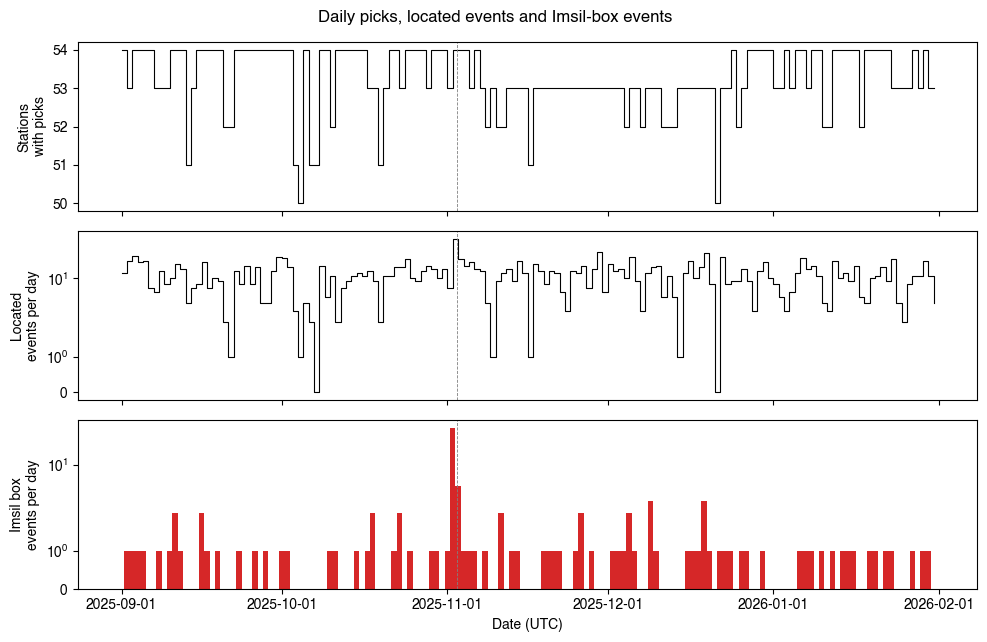

days with picks: 153 of 153; days without picks: none
picks: 1123147 (484833 P, 638314 S); median stations with picks per day 53


In [3]:
status = pd.read_csv(f'{DL}/logs/full_run_status.csv'); display(status[status.year.isin(YEARS)])
pk = []
for y in YEARS:
    for f in sorted(glob.glob(f'{config.picks_dir(MODEL, y)}/picks_{y}.*.csv')):
        d = pd.read_csv(f); doy = int(f.split('.')[-2])
        day = pd.Timestamp(f'{y}-01-01') + pd.Timedelta(days=doy - 1)
        if T0 <= day < T1:
            pk.append(dict(date=day, picks=len(d), p=int((d.phase == 'P').sum()), s=int((d.phase == 'S').sum()), stations=d.station.nunique()))
pk = pd.DataFrame(pk).set_index('date')
days = pd.date_range(T0, T1 - pd.Timedelta(days=1)); missing_days = [d.date() for d in days if d not in pk.index]
loc_day = cat.groupby(cat.time.dt.normalize()).size().reindex(days, fill_value=0)
box_day = cat[cat.in_imsil_box].groupby(cat.time.dt.normalize()).size().reindex(days, fill_value=0)
fig, ax = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
ax[0].step(pk.index, pk.stations, where='post', color='black', lw=0.8); ax[0].set_ylabel('Stations\nwith picks')
ax[1].step(days, loc_day.values, where='post', color='black', lw=0.8); ax[1].set_ylabel('Located\nevents per day'); ax[1].set_yscale('symlog')
ax[2].bar(days, box_day.values, width=1, color='tab:red'); ax[2].set_ylabel('Imsil box\nevents per day'); ax[2].set_yscale('symlog')
for a in ax: a.axvline(SWARM0, color='gray', lw=0.6, ls='--')
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d')); ax[2].set_xlabel('Date (UTC)')
fig.suptitle('Daily picks, located events and Imsil-box events'); plt.tight_layout(); plt.show()
print(f'days with picks: {len(pk)} of {len(days)}; days without picks: {missing_days if missing_days else "none"}')
print(f'picks: {int(pk.picks.sum())} ({int(pk.p.sum())} P, {int(pk.s.sum())} S); median stations with picks per day {int(pk.stations.median())}')

### Repaired days (decision D19)
On 2025-12-09 and 2025-12-22, 21 and 22 station-day files each held one or two junk records. These records carried an impossible start time and 3–4 samples, at the point where the data stop for up to a minute (05:44–05:45 UTC). ObsPy rejects a whole file on such a record, so the original run lost those station-days.

The repaired copies keep every other record byte for byte and leave out only the junk records. The MARA archive is untouched. Detection and location for those days were re-run on the copies.

In [4]:
man = pd.read_csv(f'{PROJECT}/continuous_repaired/repair_manifest.csv', dtype={'day': str})
old = {d: pd.read_csv(f'{DL}/models/phasenet_plus/detection_location/2025/picks_pre_d19/picks_2025.{d}.csv') for d in ('343', '356')}
rep = pd.DataFrame([dict(day=f'2025.{d}', files_repaired=int((man.day == f'2025.{d}').sum()), stub_records=int(man[man.day == f'2025.{d}'].n_stub.sum()),
                         picks_before=len(old[d]), stations_before=old[d].station.nunique(),
                         picks_after=int(pk.loc[pd.Timestamp('2025-01-01') + pd.Timedelta(days=int(d) - 1), 'picks']),
                         stations_after=int(pk.loc[pd.Timestamp('2025-01-01') + pd.Timedelta(days=int(d) - 1), 'stations'])) for d in ('343', '356')])
display(rep)

,day,files_repaired,stub_records,picks_before,stations_before,picks_after,stations_after
0,2025.343,28,28,3799,31,8288,53
1,2025.356,22,22,6009,32,8643,53


## 3. KMA events recovered

Two comparisons: the 24 KMA-listed Imsil events, and every KMA event in the association box during the period.

In [5]:
k24 = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str}, parse_dates=['origin_time_UTC'])
def match(t, tol=12):
    d = (cat.time - t).dt.total_seconds().abs(); i = d.idxmin()
    return (i, float(d[i])) if d[i] <= tol else (None, np.nan)
m24 = [match(t) for t in k24.origin_time_UTC]
k24['found'] = [i is not None for i, _ in m24]; k24['dt_s'] = [d for _, d in m24]
k24['tier'] = [cat.tier[i] if i is not None else '' for i, _ in m24]
n24 = int(k24.found.sum()); print(f'KMA-listed Imsil events recovered: {n24} of 24; tiers {k24.tier.value_counts().to_dict()}')
kma = pd.read_csv(f'{PROJECT}/data/catalogs/kma_entire_catalog_260309.csv', encoding='utf-8-sig', parse_dates=['time'])
kma['time'] = kma.time - pd.Timedelta(hours=9)
la, lo = config.REGION_STRICT['lat'], config.REGION_STRICT['lon']
kr = kma[(kma.time >= T0) & (kma.time < T1) & kma.latitude.between(*la) & kma.longitude.between(*lo)].copy()
mk = [match(t) for t in kr.time]; kr['found'] = [i is not None for i, _ in mk]
kr['dist_imsil_km'] = dist_km(kr.latitude, kr.longitude).round(1)
display(kr[['time', 'latitude', 'longitude', 'magnitude', 'dist_imsil_km', 'found']].sort_values('time'))
print(f'KMA events in the association box and period: {len(kr)}; recovered {int(kr.found.sum())}')

KMA-listed Imsil events recovered: 24 of 24; tiers {'A': 24}


,time,latitude,longitude,magnitude,dist_imsil_km,found
13867,2025-09-01 13:13:24,34.90,127.43,1.3,73.4,True
13891,2025-09-09 05:57:54,35.43,127.93,1.5,59.0,True
13894,2025-09-10 09:50:22,36.20,128.06,1.2,100.0,False
13899,2025-09-11 15:54:50,35.65,126.73,1.7,52.3,True
13930,2025-09-23 06:27:03,35.45,127.76,1.4,43.5,True
...,...,...,...,...,...,...
14292,2026-01-16 20:02:21,35.83,127.69,1.1,47.3,True
14296,2026-01-18 15:16:13,35.62,127.66,1.8,33.9,True
14316,2026-01-24 11:14:52,36.24,127.23,1.4,76.9,True
14330,2026-01-29 11:52:25,35.69,126.72,1.3,54.3,True


KMA events in the association box and period: 89; recovered 86


## 4. Where the events are

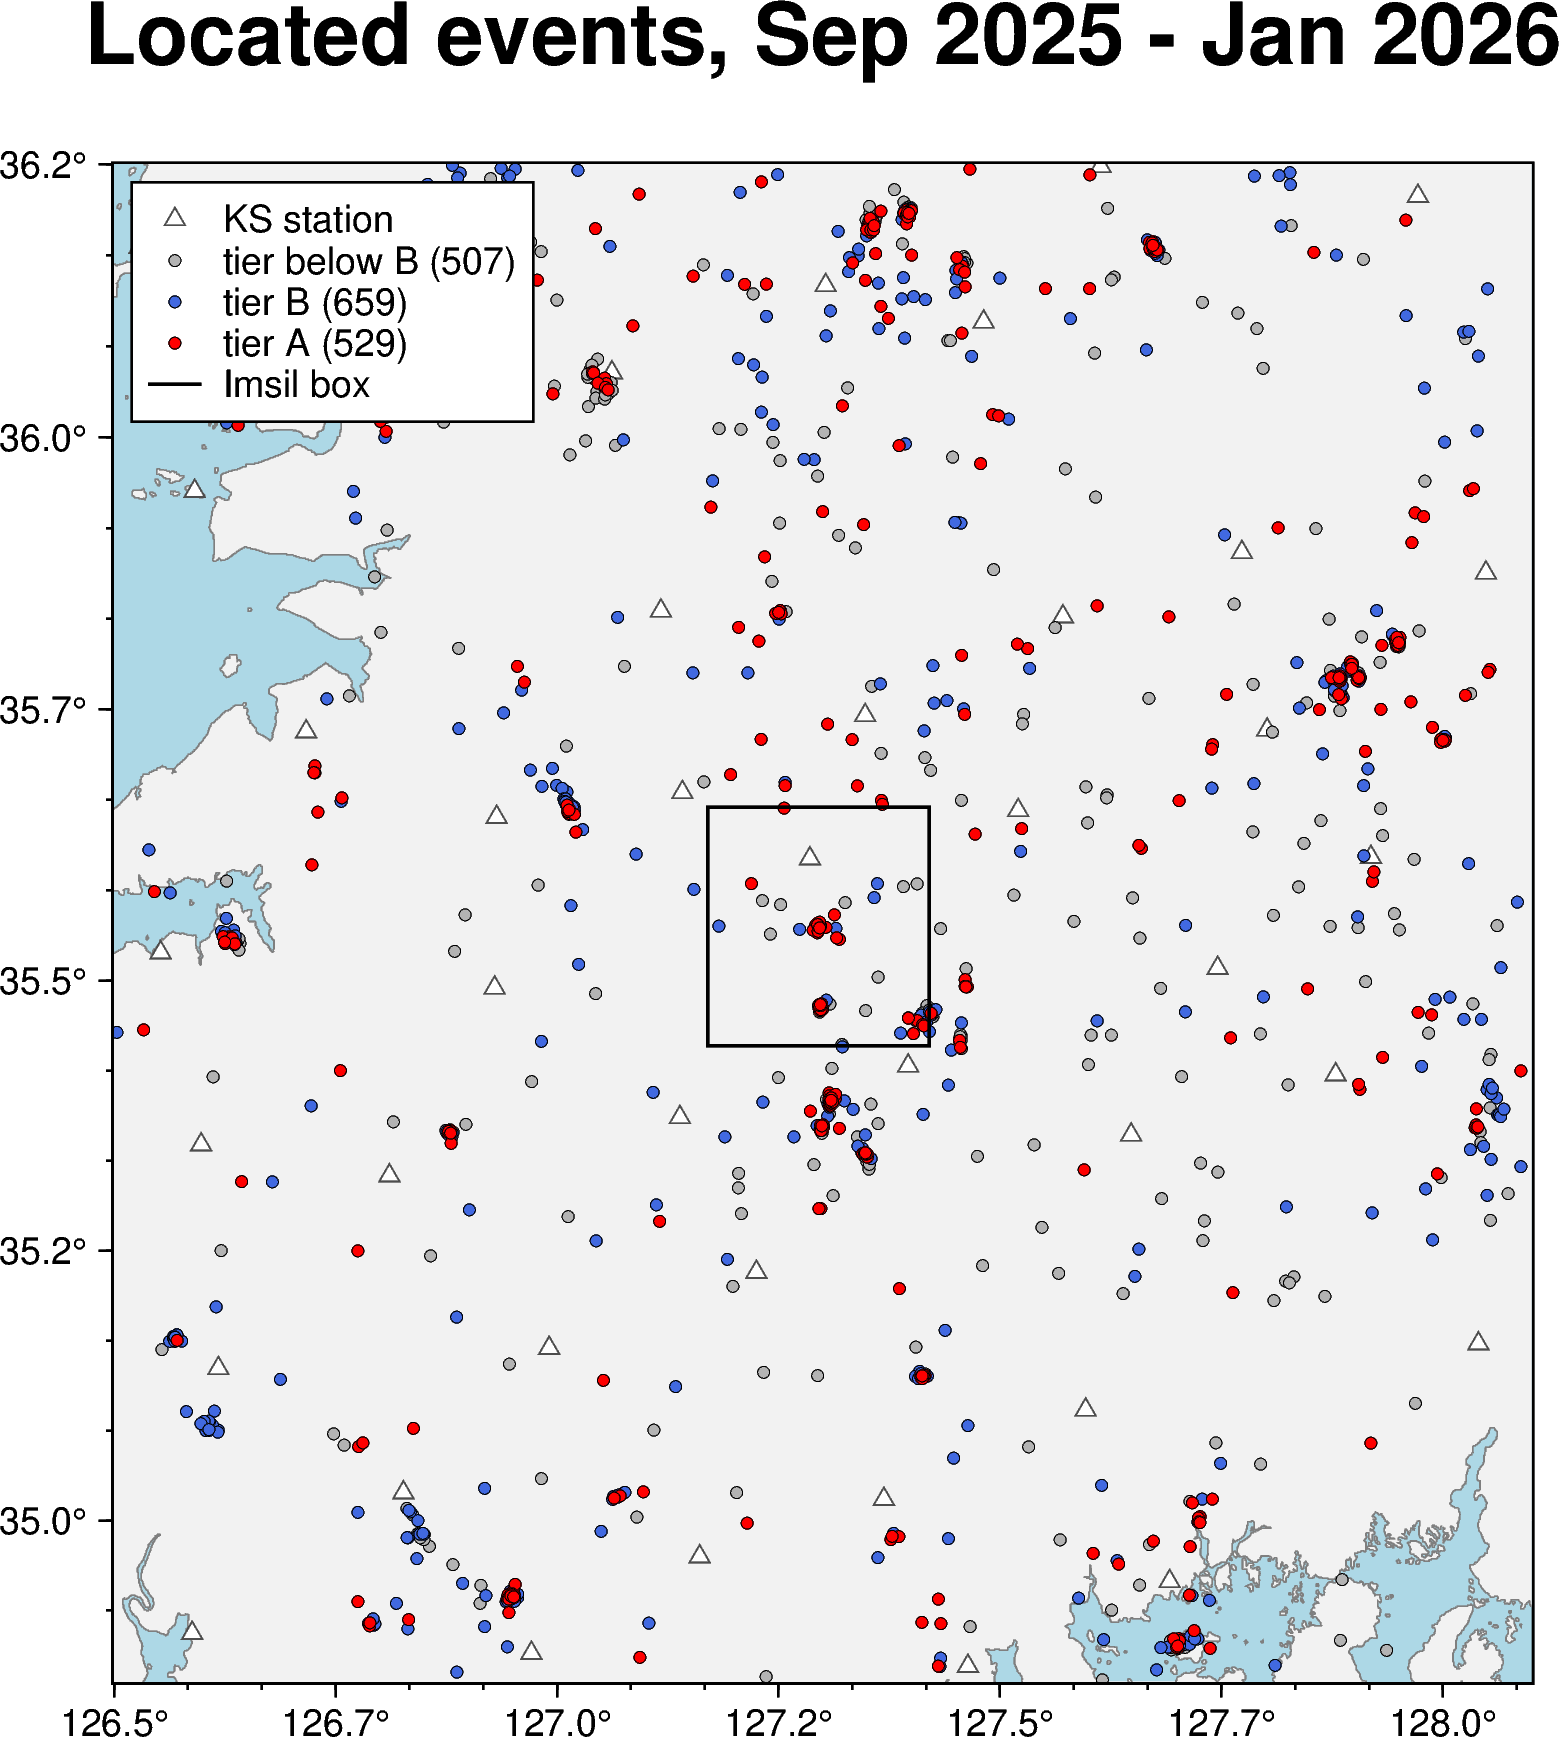

In [6]:
fig = pygmt.Figure()
pygmt.config(FORMAT_GEO_MAP='ddd.x', MAP_FRAME_TYPE='plain', FONT_ANNOT_PRIMARY='9p', FONT_LABEL='9p')
fig.basemap(region=[lo[0], lo[1], la[0], la[1]], projection='M12c', frame=['af', '+tLocated events, Sep 2025 - Jan 2026'])
fig.coast(land='gray95', water='lightblue', shorelines='0.3p,gray50')
st = pd.read_csv(config.STATIONS_CSV)
fig.plot(x=st.Longitude, y=st.Latitude, style='t0.2c', fill='white', pen='0.3p,gray30', label='KS station')
for t, col in (('-', 'gray70'), ('B', 'royalblue'), ('A', 'red')):
    g = cat[cat.tier == t]
    if len(g): fig.plot(x=g.lon, y=g.lat, style='c0.1c', fill=col, pen='0.1p,black', label=f'tier {t if t != "-" else "below B"} ({len(g)})')
b = config.IMSIL_BOX
fig.plot(x=[b[2], b[3], b[3], b[2], b[2]], y=[b[0], b[0], b[1], b[1], b[0]], pen='0.8p,black', label='Imsil box')
fig.legend(position='JTL+jTL+o0.15c', box='+gwhite+p0.5p'); fig.show()

## 5. The Imsil box over time and depth

The kim1983 model has an interface at 15 km. Events near 13–15 km should be checked for a pile-up at the interface.

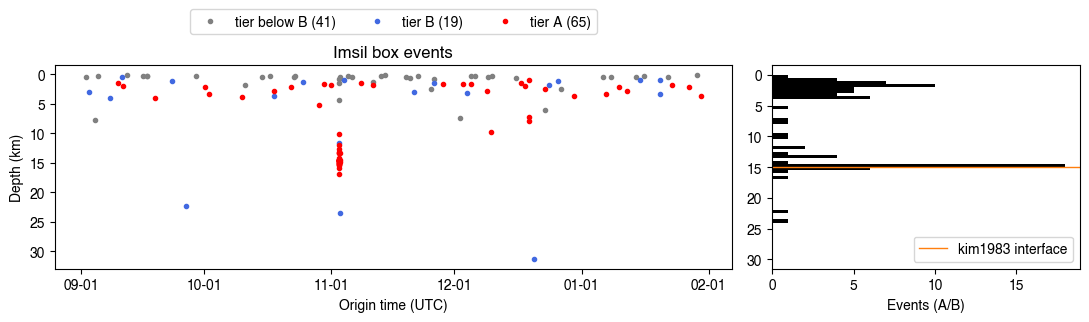

Imsil box: 125 events (84 A/B); before the swarm 31, swarm window 39, after 55
in-box events shallower than 10 km (removed by the relocation depth floor, D5): 87
2 Nov in the box: this run 35; earlier PhaseNO + PyOcto run (11 stations) 33


In [7]:
bx = cat[cat.in_imsil_box].copy()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[2.2, 1]))
for t, col in (('-', 'gray'), ('B', 'royalblue'), ('A', 'red')):
    g = bx[bx.tier == t]; ax[0].plot(g.time, g.depth, 'o', ms=3, color=col, label=f'tier {t if t != "-" else "below B"} ({len(g)})')
ax[0].invert_yaxis(); ax[0].set_ylabel('Depth (km)'); ax[0].set_xlabel('Origin time (UTC)'); ax[0].set_title('Imsil box events')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.12), ncol=3, frameon=True); ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
ax[1].hist(bx[bx.tier.isin(['A', 'B'])].depth, bins=np.arange(0, 30.5, 0.5), color='black', orientation='horizontal')
ax[1].axhline(15, color='tab:orange', lw=1, label='kim1983 interface'); ax[1].invert_yaxis(); ax[1].set_xlabel('Events (A/B)'); ax[1].legend(loc='lower right')
plt.tight_layout(); plt.show()
swarm = bx[(bx.time >= SWARM0) & (bx.time <= SWARM1)]; before = bx[bx.time < SWARM0]; after = bx[bx.time > SWARM1]
print(f'Imsil box: {len(bx)} events ({bx.tier.isin(["A", "B"]).sum()} A/B); before the swarm {len(before)}, swarm window {len(swarm)}, after {len(after)}')
shallow = bx[bx.depth < 10]; print(f'in-box events shallower than 10 km (removed by the relocation depth floor, D5): {len(shallow)}')
prev = pd.read_csv(f'{PROJECT}/4.PyOcto/251102/pyocto_kim1983_prob0.5.csv', parse_dates=['time'])
prev_box = prev[prev.latitude.between(b[0], b[1]) & prev.longitude.between(b[2], b[3])]
nov2 = bx[(bx.time >= '2025-11-02') & (bx.time < '2025-11-03')]
print(f'2 Nov in the box: this run {len(nov2)}; earlier PhaseNO + PyOcto run (11 stations) {len(prev_box)}')

## Comprehensive summary

In [8]:
summary = pd.DataFrame([
    ('Frozen parameters equal Haenam except the association box and D17', params_ok),
    ('Days with picks / days in period', f'{len(pk)} / {len(days)}'),
    ('Picks (P / S)', f'{int(pk.p.sum())} / {int(pk.s.sum())}'),
    ('Located events (A / B / below B)', f'{(cat.tier == "A").sum()} / {(cat.tier == "B").sum()} / {(cat.tier == "-").sum()}'),
    ('Imsil box events (A/B)', f'{len(bx)} ({bx.tier.isin(["A", "B"]).sum()})'),
    ('Imsil box: before / swarm window / after', f'{len(before)} / {len(swarm)} / {len(after)}'),
    ('KMA-listed Imsil events recovered', f'{n24} of 24'),
    ('KMA events in the association box recovered', f'{int(kr.found.sum())} of {len(kr)}'),
    ('Repaired days (D19): files / picks before -> after', '; '.join(f'{r.day}: {r.files_repaired} / {r.picks_before} -> {r.picks_after}' for r in rep.itertuples())),
], columns=['quantity', 'value'])
display(summary)
print('Take-home points')
print(f'  - The frozen Haenam detection recovers {n24} of the 24 KMA-listed Imsil events and {int(kr.found.sum())} of {len(kr)} KMA events in the region.')
print(f'  - The Imsil box holds {len(bx)} located events, {len(before)} before and {len(after)} after the swarm window; they are candidates for relocation (notebook 04).')
print('Next: ./run_imsil.sh dl-reloc --years 2025-2026 --min-depth 10 --open-wdcc --n-boot 1000 --blocked-pairs 45 run (notebook 04).')

,quantity,value
0,Frozen parameters equal Haenam except the asso...,True
1,Days with picks / days in period,153 / 153
2,Picks (P / S),484833 / 638314
3,Located events (A / B / below B),529 / 659 / 507
4,Imsil box events (A/B),125 (84)
5,Imsil box: before / swarm window / after,31 / 39 / 55
6,KMA-listed Imsil events recovered,24 of 24
7,KMA events in the association box recovered,86 of 89
8,Repaired days (D19): files / picks before -> a...,2025.343: 28 / 3799 -> 8288; 2025.356: 22 / 60...


Take-home points
  - The frozen Haenam detection recovers 24 of the 24 KMA-listed Imsil events and 86 of 89 KMA events in the region.
  - The Imsil box holds 125 located events, 31 before and 55 after the swarm window; they are candidates for relocation (notebook 04).
Next: ./run_imsil.sh dl-reloc --years 2025-2026 --min-depth 10 --open-wdcc --n-boot 1000 --blocked-pairs 45 run (notebook 04).
